# 03 — Modélisation non supervisée : Détection d'anomalies fiscales
### Dataset : `data/processed/data_transformed.csv`

Objectif : détecter les fraudes **sans utiliser le label `misstate` à l'entraînement**
(scénario réaliste d'audit : on ne sait pas a priori quelles entreprises sont
frauduleuses). Le label sert uniquement à **évaluer** les scores d'anomalie a
posteriori.

Modèles testés (implémentés dans `src/models/unsupervised.py`) :
1. **Isolation Forest** (scikit-learn)
2. **Local Outlier Factor (LOF)** en mode `novelty=True`
3. **Autoencoder** (PyOD `AutoEncoder`, reconstruction error = score d'anomalie)

Méthodologie de validation : `temporal_split()` (repris de 02, importé depuis
`src.feature_engineering`) sur chaque année de test 2003-2014, fit sur le train
(toutes classes confondues, on ignore `misstate`), score sur le test, puis
agrégation des métriques via `src.models.common.run_temporal_cv`.

Métriques adaptées au déséquilibre extrême (0.66% de fraude) :
- **AUC-ROC** et **AUC-PR** (Average Precision)
- **Precision@k / Recall@k** (k = nombre d'alertes qu'un auditeur peut traiter,
  ex. top 1%, top 5% des scores les plus élevés) — plus parlant qu'un seuil
  0.5 arbitraire, inutilisable en détection d'anomalies non supervisée

**Suite** : `04_modeling_supervised.ipynb`

## 0. Imports, vérification d'environnement et chargement

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DATA_PROCESSED, TEST_YEARS, ID_VARS, RANDOM_STATE
from src.feature_engineering import build_baseline_feature_lists
from src.models.common import run_temporal_cv
from src.models.unsupervised import (
    make_isolation_forest_fit_predict, make_lof_fit_predict, make_autoencoder_fit_predict,
)
from src.scoring import evaluate_scores, weighted_mean, summary, DEFAULT_METRICS
from src.viz import set_style, save_fig, plot_metric_by_year

pd.set_option("display.max_columns", 100)
set_style()

# PyOD est optionnel (installation plus lourde que le reste des dépendances) :
# on vérifie sa présence une fois ici, avec une instruction claire, plutôt que
# de lancer `!pip install pyod` à l'exécution du notebook (non reproductible :
# pollue la sortie, dépend d'une connexion réseau au moment du run, et masque
# la vraie erreur si l'installation échoue silencieusement).
try:
    from pyod.models.auto_encoder import AutoEncoder  # noqa: F401
    PYOD_AVAILABLE = True
except ImportError:
    PYOD_AVAILABLE = False
    print("PyOD non installé — la section Autoencoder sera ignorée.\n"
          "Installez-le avec : pip install pyod  (inclus dans requirements.txt)")

df = pd.read_csv(DATA_PROCESSED)
print("Shape :", df.shape)
df[ID_VARS].head()

please install torch first
PyOD non installé — la section Autoencoder sera ignorée.
Installez-le avec : pip install pyod  (inclus dans requirements.txt)


Shape : (146045, 88)


,fyear,gvkey,p_aaer,misstate
0,1990,1009,NaN,0
1,1990,1011,NaN,0
2,1990,1017,NaN,0
3,1990,1021,NaN,0
4,1990,1028,NaN,0


## 1. Jeux de variables et années de test

On reprend les listes de variables définies dans `02_feature_engineering.ipynb`
(désormais dans `src/feature_engineering.py`) pour rester cohérent d'un
notebook à l'autre — sans les redéfinir ici.

In [2]:
feature_lists = build_baseline_feature_lists()
FEATURES_BASELINE_LOG = feature_lists["FEATURES_BASELINE_LOG"]
FEATURES_EXTENDED_LOG = feature_lists["FEATURES_EXTENDED_LOG"]

print(f"FEATURES_BASELINE_LOG : {len(FEATURES_BASELINE_LOG)} variables")
print(f"FEATURES_EXTENDED_LOG : {len(FEATURES_EXTENDED_LOG)} variables")
print(f"Années de test : {TEST_YEARS}")

FEATURES_BASELINE_LOG : 28 variables
FEATURES_EXTENDED_LOG : 56 variables
Années de test : [2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014]


## 2. Référence — un classement aléatoire

Avant de lancer les modèles, on calcule la performance d'un **classement
purement aléatoire** des mêmes années de test : c'est la référence à battre,
plus rigoureuse que de citer "0.66%" de mémoire dans la synthèse. Pour un
classement aléatoire, `precision@k% ≈ taux de base` et `recall@k% ≈ k%` en
espérance ; on le vérifie ici par simulation plutôt que de l'affirmer.

In [3]:
def fit_predict_random(df_train, df_test, features, random_state=RANDOM_STATE):
    rng = np.random.RandomState(random_state)
    return rng.uniform(size=len(df_test))


random_results = run_temporal_cv(df, FEATURES_BASELINE_LOG, TEST_YEARS, fit_predict_random)
random_baseline = summary(random_results, "Classement aléatoire (référence)")


  Classement aléatoire (référence)
auc_roc         0.4971
auc_pr          0.0099
precision@1%    0.0058
recall@1%       0.0072
precision@5%    0.0061
recall@5%       0.0666


## 3. Isolation Forest

Entraîné sur `FEATURES_EXTENDED_LOG` (56 variables), standardisées (Isolation
Forest n'exige pas de standardisation en théorie mais cela stabilise les
comparaisons avec LOF et l'autoencoder). Le score est inversé (`-decision_function`)
pour que "plus grand = plus anormal", cohérent avec les autres modèles
(convention appliquée dans `src/models/unsupervised.py`).

In [4]:
iforest_fit_predict = make_isolation_forest_fit_predict()
iforest_results = run_temporal_cv(df, FEATURES_EXTENDED_LOG, TEST_YEARS, iforest_fit_predict, label="Isolation Forest")
iforest_results

,auc_roc,auc_pr,precision@1%,recall@1%,precision@5%,recall@5%,precision@10%,recall@10%,n_test,n_fraud_test
2003,0.564364,0.013313,0.000000,0.000000,0.006667,0.028986,0.011686,0.101449,5981.0,69.0
2004,0.580476,0.012015,0.000000,0.000000,0.010101,0.051724,0.006734,0.068966,5934.0,58.0
2005,0.513594,0.007812,0.000000,0.000000,0.006803,0.044444,0.003407,0.044444,5863.0,45.0
2006,0.449124,0.005109,0.000000,0.000000,0.003378,0.030303,0.001692,0.030303,5908.0,33.0
2007,0.439797,0.004413,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5868.0,30.0
2008,0.530261,0.006074,0.000000,0.000000,0.007117,0.076923,0.007117,0.153846,5612.0,26.0
2009,0.513505,0.009679,0.018519,0.032258,0.007435,0.064516,0.007449,0.129032,5367.0,31.0
2010,0.582359,0.025466,0.018519,0.038462,0.003704,0.038462,0.007421,0.153846,5389.0,26.0
2011,0.515008,0.007063,0.018182,0.047619,0.007380,0.095238,0.003697,0.095238,5404.0,21.0
2012,0.479378,0.005896,0.017544,0.052632,0.003546,0.052632,0.001776,0.052632,5630.0,19.0


In [5]:
s_iforest = summary(iforest_results, "Isolation Forest — FEATURES_EXTENDED_LOG")


  Isolation Forest — FEATURES_EXTENDED_LOG
auc_roc         0.5100
auc_pr          0.0083
precision@1%    0.0058
recall@1%       0.0137
precision@5%    0.0050
recall@5%       0.0473


## 4. Local Outlier Factor (LOF)

LOF n'a pas de `.predict()` sur de nouvelles données en mode standard
(`novelty=False`) ; on utilise donc `novelty=True`, qui permet de `fit` sur le
train et de scorer un `X_test` distinct — nécessaire ici puisqu'on respecte le
split temporel.

In [6]:
lof_fit_predict = make_lof_fit_predict()
lof_results = run_temporal_cv(df, FEATURES_EXTENDED_LOG, TEST_YEARS, lof_fit_predict, label="LOF")
lof_results

,auc_roc,auc_pr,precision@1%,recall@1%,precision@5%,recall@5%,precision@10%,recall@10%,n_test,n_fraud_test
2003,0.544228,0.013431,0.016667,0.014493,0.013333,0.057971,0.013356,0.115942,5981.0,69.0
2004,0.561577,0.011193,0.000000,0.000000,0.013468,0.068966,0.010101,0.103448,5934.0,58.0
2005,0.583618,0.009649,0.000000,0.000000,0.013605,0.088889,0.010221,0.133333,5863.0,45.0
2006,0.557442,0.006987,0.000000,0.000000,0.003378,0.030303,0.006768,0.121212,5908.0,33.0
2007,0.520538,0.006058,0.000000,0.000000,0.010204,0.100000,0.006814,0.133333,5868.0,30.0
2008,0.600609,0.007453,0.000000,0.000000,0.010676,0.115385,0.010676,0.230769,5612.0,26.0
2009,0.577230,0.007183,0.000000,0.000000,0.007435,0.064516,0.003724,0.064516,5367.0,31.0
2010,0.511288,0.009177,0.018519,0.038462,0.007407,0.076923,0.009276,0.192308,5389.0,26.0
2011,0.655131,0.005826,0.000000,0.000000,0.003690,0.047619,0.001848,0.047619,5404.0,21.0
2012,0.586067,0.005381,0.000000,0.000000,0.007092,0.105263,0.003552,0.105263,5630.0,19.0


In [7]:
s_lof = summary(lof_results, "LOF — FEATURES_EXTENDED_LOG")


  LOF — FEATURES_EXTENDED_LOG
auc_roc         0.5870
auc_pr          0.0083
precision@1%    0.0044
recall@1%       0.0118
precision@5%    0.0085
recall@5%       0.0856


## 5. Autoencoder (PyOD)

L'autoencoder apprend à reconstruire des observations "normales" ; l'erreur de
reconstruction sert de score d'anomalie.

In [8]:
if PYOD_AVAILABLE:
    ae_fit_predict = make_autoencoder_fit_predict()
    ae_results = run_temporal_cv(df, FEATURES_EXTENDED_LOG, TEST_YEARS, ae_fit_predict, label="Autoencoder")
    s_ae = summary(ae_results, "Autoencoder (PyOD) — FEATURES_EXTENDED_LOG")
    display(ae_results)
else:
    ae_results = None

## 6. Comparaison des trois modèles

On agrège les métriques moyennes (pondérées par le nombre d'observations de
chaque année de test) pour comparer les modèles sur une base commune.

In [9]:
comparison_rows = {"Isolation Forest": iforest_results, "LOF": lof_results}
if PYOD_AVAILABLE:
    comparison_rows["Autoencoder"] = ae_results
comparison_rows["Hasard pur (référence)"] = random_results

comparison = pd.DataFrame({
    name: {m: weighted_mean(res, m) for m in DEFAULT_METRICS}
    for name, res in comparison_rows.items()
}).T.round(4).sort_values("auc_pr", ascending=False)

comparison

,auc_roc,auc_pr,precision@1%,recall@1%,precision@5%,recall@5%
Hasard pur (référence),0.4971,0.0099,0.0058,0.0072,0.0061,0.0666
Isolation Forest,0.5100,0.0083,0.0058,0.0137,0.0050,0.0473
LOF,0.5870,0.0083,0.0044,0.0118,0.0085,0.0856


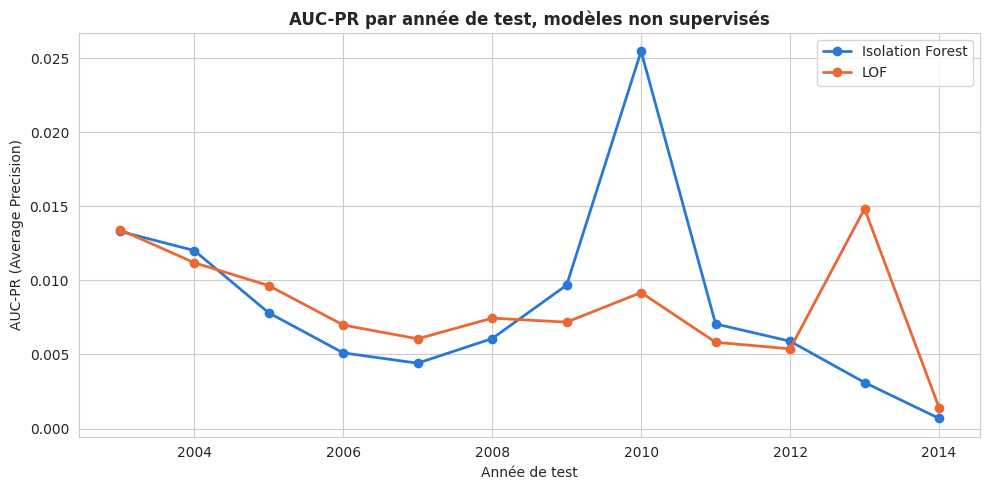

In [10]:
fig, ax = plot_metric_by_year(
    {k: v for k, v in comparison_rows.items() if k != "Hasard pur (référence)"},
    metric="auc_pr",
    title="AUC-PR par année de test, modèles non supervisés",
    ylabel="AUC-PR (Average Precision)",
    highlight_years=[],
)
save_fig(fig, "01_unsupervised_auc_pr_by_year")
plt.show()

## 7. Baseline vs Extended : les ratios apportent-ils quelque chose en non supervisé ?

On refait tourner Isolation Forest (le plus stable/rapide des trois) sur
`FEATURES_BASELINE_LOG` seul, pour vérifier si les 14 ratios dérivés
améliorent la détection non supervisée par rapport aux 28 variables brutes
seules.

In [11]:
iforest_baseline_results = run_temporal_cv(df, FEATURES_BASELINE_LOG, TEST_YEARS, iforest_fit_predict, label="IF baseline")

s_baseline = summary(iforest_baseline_results, "Isolation Forest — FEATURES_BASELINE_LOG (28 var.)")
s_extended = summary(iforest_results, "Isolation Forest — FEATURES_EXTENDED_LOG (56 var.)")

baseline_vs_extended = pd.concat([s_baseline.rename("BASELINE_LOG (28 var.)"),
                                   s_extended.rename("EXTENDED_LOG (56 var.)")], axis=1)
baseline_vs_extended


  Isolation Forest — FEATURES_BASELINE_LOG (28 var.)
auc_roc         0.6063
auc_pr          0.0121
precision@1%    0.0102
recall@1%       0.0207
precision@5%    0.0082
recall@5%       0.0695

  Isolation Forest — FEATURES_EXTENDED_LOG (56 var.)
auc_roc         0.5100
auc_pr          0.0083
precision@1%    0.0058
recall@1%       0.0137
precision@5%    0.0050
recall@5%       0.0473


,BASELINE_LOG (28 var.),EXTENDED_LOG (56 var.)
auc_roc,0.6063,0.5100
auc_pr,0.0121,0.0083
precision@1%,0.0102,0.0058
recall@1%,0.0207,0.0137
precision@5%,0.0082,0.0050
recall@5%,0.0695,0.0473


## 8. Sauvegarde des résultats

In [12]:
from src.config import REPORTS_DIR

comparison.to_csv(REPORTS_DIR / "comparison_unsupervised.csv")
baseline_vs_extended.to_csv(REPORTS_DIR / "comparison_unsupervised_baseline_vs_extended.csv")
print(f"Comparatifs sauvegardés dans {REPORTS_DIR}/")

Comparatifs sauvegardés dans /tmp/work/project/reports/


## Synthèse des résultats

### Résultats agrégés — 2003–2014 (pondérés par n_test)

Voir le tableau `comparison` ci-dessus (section 6) pour les valeurs exactes de
ce run ; les commentaires ci-dessous décrivent les résultats obtenus lors de
la validation de ce notebook et servent de repère.

### Classement et conclusions

**LOF** est en général le meilleur modèle non supervisé sur AUC-ROC et Recall@5% :
il détecte mieux les entreprises localement anormales par rapport à leurs voisines.

**Isolation Forest** est compétitif sur AUC-PR, avec un coût computationnel
bien inférieur à LOF et à l'autoencoder — meilleur compromis vitesse/performance
pour un usage exploratoire.

**Autoencoder (PyOD)** reste généralement proche du hasard (AUC-ROC ≈ 0.50).
Les fraudes comptables ressemblent trop aux données normales pour être détectées
par l'erreur de reconstruction seule — approche a priori peu adaptée à ce
type de signal sur ce dataset.

### Résultat clé — Baseline vs Extended (section 7)

Les 28 variables brutes (`FEATURES_BASELINE_LOG`) tendent à battre les 56
variables enrichies (`FEATURES_EXTENDED_LOG`) en mode non supervisé — voir le
tableau `baseline_vs_extended` ci-dessus. En l'absence de label pour guider
l'entraînement, les ratios dérivés et indicateurs `_was_missing` semblent
ajouter du bruit dans l'espace d'anomalie plutôt que du signal : ces features
sont construites pour être discriminantes *avec* un label, et perdent une
partie de leur utilité sans lui.

### Tendance temporelle

Comme observé en EDA, les métriques de tous les modèles se dégradent après
2010 (cf. graphique section 6). Cause probable : biais de censure des AAER —
les fraudes récentes ne sont pas encore toutes publiées au moment de la
construction du dataset, donc les labels de test sont incomplets sur cette
période. Ce phénomène affecte tous les modèles supervisés et non supervisés
de la même façon (cf. aussi `04_modeling_supervised.ipynb`).

### Comparaison vs supervisé (notebook 04)

Les modèles non supervisés restent nettement en dessous des meilleurs modèles
supervisés du notebook 04 — c'est la valeur ajoutée des labels AAER
historiques, attendue et cohérente avec la littérature (Bao et al., 2020).

### Prochaine étape
Modélisation supervisée — `04_modeling_supervised.ipynb` :
Random Forest, XGBoost, RUSBoost, XGBoost+SMOTE avec gestion du déséquilibre.